In [1]:
## -- System dependencies -- 
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
from time import time, sleep
from tqdm.auto import tqdm
import itertools

## -- Machine Learning --
# import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold, train_test_split
from sklearn.preprocessing import (
                StandardScaler, RobustScaler, OneHotEncoder,
                QuantileTransformer, PowerTransformer, TargetEncoder as skTE
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay

from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb
except:
    !uv pip install --system xgboost
    import xgboost as xgb

try:
    import lightgbm as lgb
except:
    !uv pip install --system lightgbm
    import lightgbm as lgb

try:
    import catboost as cgb
except:
    !uv pip install --system catboost
    import catboost as cgb

print(f"xgboost  version: {xgb.__version__}")
print(f"lightgbm version: {lgb.__version__}")
print(f"catboost version: {cgb.__version__}")

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 1000)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

xgboost  version: 3.4.1
lightgbm version: 4.6.0
catboost version: 1.2.10


In [4]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [5]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropping!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropping!


In [6]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

# train = train[base_cols+[TARGET]]
# orig  = orig[base_cols+[TARGET]]
# test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")
    
print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test shape: (299984, 24)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [7]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return sample_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return sample_weights

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [8]:
display(train.head())
train.info()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    699960 non-null  float64
 1   hours_since_last_txn          699960 non-null  float64
 2   txn_count_last_24h            699960 non-null  int64  
 3   distance_from_home_km         699960 non-null  float64
 4   card_age_months               699960 non-null  int64  
 5   customer_age                  699960 non-null  int64  
 6   account_balance_usd           699960 non-null  float64
 7   cvv_retry_count               699960 non-null  int64  
 8   velocity_score                699960 non-null  float64
 9   time_of_day_hour              699960 non-null  int64  
 10  day_of_week                   699960 non-null  int64  
 11  merchant_risk_score           699960 non-null  float64
 12  prior_disputes                699960 non-nul

In [9]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


In [10]:
train.describe(exclude=np.number).T\
.style.bar(subset=["freq"], color="#24b8eb")

,count,unique,top,freq
merchant_category,699960,12,Online Retail,155097
card_type,699960,5,Visa,345001
auth_method,699960,5,3D Secure,210036
channel,699960,5,Online,273939
device_type,699960,8,Android Phone,237454
is_foreign_transaction,699960,2,False,687862
is_new_merchant,699960,2,False,593240
used_vpn,699960,2,False,676295
ip_country_mismatch,699960,2,False,688648
billing_shipping_mismatch,699960,2,False,690906


In [11]:
display(test.head())
test.info()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,3,22.1,0,Fuel,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,9,1,25.1,0,Travel,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,2,4,52.9,1,Gaming,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,8,5,35.4,0,Streaming,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,14,5,44.5,0,Groceries,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 24 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    299984 non-null  float64
 1   hours_since_last_txn          299984 non-null  float64
 2   txn_count_last_24h            299984 non-null  int64  
 3   distance_from_home_km         299984 non-null  float64
 4   card_age_months               299984 non-null  int64  
 5   customer_age                  299984 non-null  int64  
 6   account_balance_usd           299984 non-null  float64
 7   cvv_retry_count               299984 non-null  int64  
 8   velocity_score                299984 non-null  float64
 9   time_of_day_hour              299984 non-null  int64  
 10  day_of_week                   299984 non-null  int64  
 11  merchant_risk_score           299984 non-null  float64
 12  prior_disputes                299984 non-nul

In [12]:
# display(orig.head())
# orig.info()

In [13]:
# Check if column names are the same regardless of order
are_same_set = set(train.columns) == set(orig.columns)
print(f"Are column names the same regardless of order (train vs orig)? {are_same_set}")

# Check if column names are the same and in the same order
are_same_exact = train.columns.equals(orig.columns)
print(f"Are column names exactly the same and in the same order (train vs orig)? {are_same_exact}")

Are column names the same regardless of order (train vs orig)? False
Are column names exactly the same and in the same order (train vs orig)? False


In [15]:
## -- Unique value counts for each dataset --
TRAIN_UNIQUE = {}
ORIGINAL_UNIQUE = {}
TEST_UNIQUE = {}

for col in base_cols:
    TRAIN_UNIQUE[col] = train[col].nunique()
    ORIGINAL_UNIQUE[col] = orig[col].nunique()
    TEST_UNIQUE[col] = test[col].nunique()

unique_counts_df = pd.concat([
    pd.DataFrame(ORIGINAL_UNIQUE, index=['orig']),
    pd.DataFrame(TEST_UNIQUE, index=['test']),
    pd.DataFrame(TRAIN_UNIQUE, index=['train']),
])

# unique_counts_df.T.sort_values(by="train").style.background_gradient(subset="Train")
v_counts = unique_counts_df.T\
.sort_values(by="train", ascending=False)\
.style.bar(subset=["train"], color="#24b8eb")

v_counts

,orig,test,train
account_balance_usd,19629,31803,43317
amount_usd,12782,10510,13387
distance_from_home_km,6121,4108,4365
hours_since_last_txn,3296,3331,3633
merchant_risk_score,940,917,950
velocity_score,634,644,666
customer_age,64,64,64
card_age_months,52,49,49
time_of_day_hour,24,24,24
txn_count_last_24h,13,11,12


### YDATA-PROFILE REPORT

In [20]:
# # %%capture

# ## -- Comprehensive EDA --
# !{sys.executable} -m pip install -qq -U ydata-profiling[notebook]
# !pip install -qq jupyter-contrib-nbextensions
# !jupyter nbextension enable --py widgetsnbextension

# from ydata_profiling import ProfileReport, compare

# ## -- Single EDA --
# # profile_df = ProfileReport(train, title="Insights into TARGET Types", explorative=True)
# # profile_df.to_notebook_iframe()

# # profile_df.to_file("Loan_EDA_Report.html")

# ## -- Create Profiles for Datasets --
# train_report = ProfileReport(train, title="Train", explorative=True)
# test_report = ProfileReport(test, title="Test", explorative=True)
# # orig_report = ProfileReport(orig, title="Original", explorative=True)

# ## -- Compare 2++ Datasets --
# comparison_report = compare([train_report, test_report])

# # ## -- Obtain merged statistics (Don't know its purpose yet)
# # statistics = comparison_report.get_description()
# ## -- Save report to file
# comparison_report.to_file("EV_Purchase | Train_Test_Stats.html")
# comparison_report.to_notebook_iframe()

# EDA

## ~ NUMERIC

In [16]:
# ## -- PLOT TARGET DISTRIBUTION --
# # plt.figure(figsize=(16, 6))
# _, axs = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios':[0.7, 0.3], 'wspace':0.1})

# ## -- KDEs --
# sns.kdeplot(data=train, x=TARGET, color=PALETTE[0], linewidth=2, ax=axs[0], label='Train')
# sns.kdeplot(data=orig, x=TARGET, color=PALETTE[1], linewidth=2, ax=axs[0], label='Original')
# axs[0].legend()
# axs[0].set_xlabel('')

# # Boxplots
# # pd.concat([train[[TARGET]], orig[[TARGET]]], axis=1).boxplot(
# #     widths=0.6,
# #     showmeans=True,
# #     # meanline=True,
# #     # patch_artist=True,
# #     # notch=True,
# #     # labels=['Train', 'Original'],
# #     ax=axs[1])

# sns.violinplot(
#     data=[train[TARGET].values, orig[TARGET].values],
#     inner='quart',
#     width=0.6,
#     # size=1,
#     # width=0.6,
#     # linewidth=2,
#     # fliersize=.1,
#     ax=axs[1],
#     palette=PALETTE)

# axs[1].set_xticklabels(['Train', 'Original'], fontdict={'weight': 'bold'})

# plt.suptitle(f"- Target '{TARGET}' distribution -", fontsize=15, fontweight='bold')
# plt.tight_layout()
# plt.show()

In [ ]:
def distplots_data(train=None, test=None, orig=None, features=None):
    # 1) Concatenate data
    df = pd.concat([
            train[features].assign(Source='Train'),
            test[features].assign(Source='Test'),
            orig[features].assign(Source='Orig'),
    ], ignore_index=True)

    for i, col in enumerate(features):
        _, axs = plt.subplots(1, 2, figsize=(12.5, 4),
            gridspec_kw={'hspace': 0.3, 'wspace': 0.15, 'width_ratios': [0.7, 0.3]},
        )
        ## -- KDE plots --
        sns.kdeplot(data=train, x=col, linewidth=2, ax=axs[0], label='Train')
        sns.kdeplot(data=test, x=col, linewidth=2, ax=axs[0], label='Test')
        sns.kdeplot(data=orig, x=col, linewidth=2, ax=axs[0], label='Orig')

        axs[0].set_title(f"{col}", loc='left')
        axs[0].set(xlabel='')
        axs[0].legend()

        ## -- BOX plots --
        sns.boxplot(
            data=df, y=col, x='Source',
            linecolor=DARK, palette=[TEAL, GOLD, CORAL],
            width=0.75, linewidth=1.0, ax=axs[1],
        )
        axs[1].set(xlabel='')
        axs[1].tick_params(axis='both', which='major')
        axs[1].set_xticklabels(['Train', 'Test', 'Orig'], weight='semibold')

        # for ax in axs:
        #     ax.grid(axis='y')

        plt.tight_layout()
        plt.show()
        print()

print("- Numerical grid plot function ready! -")

In [ ]:
num_distplots = distplots_data(train=train, test=test, features=num_cols, orig=orig) #

In [ ]:
plt.figure(figsize=(12.5, len(num_cols) + 1.5))

for i, col in enumerate(num_cols):
    plt.subplot(len(num_cols)//3 + 1, 3, i+1)
    ax = plt.hist(train[col], bins=50)
    plt.axvline(x=train[col].mean(), color='r', linestyle='--', label='mean')
    plt.axvline(x=train[col].median(), color='k', linestyle='--', label='median')
    plt.title(f"{col}", loc='left', pad=5)
    plt.legend()

plt.tight_layout(h_pad=2.0)
plt.show()

## ~ CATEGORICAL

In [ ]:
## -- Target label count --
_ = train[TARGET].value_counts(dropna=False).plot.pie(autopct='%1.2f%%', table=True)
_.set_title(f"Target label count: {TARGET}", loc="left", pad=10)
plt.show()

In [ ]:
## -- Categorical Features --
plt.figure(figsize=(12.5, 8))
# for i, col in enumerate([c for c in base_cols if train[c].nunique() <= 20]):
for i, col in enumerate(cat_cols):
    plt.subplot(2, 3, i+1)
    values=train[col].value_counts(dropna=False)
    values.plot.pie(autopct='%1.0f%%', table=True) #fontsize=12, 
    plt.title(f"Proportions of '{col}'")
    plt.axis('off')

plt.tight_layout(h_pad=3.0, w_pad=0.1)
plt.show()

In [ ]:
bin_cols = [c for c in num_cols if train[c].nunique() > 50] #[0:2]
BINS = 10

for c in bin_cols:
    # if 'Distance' in c: 
    #     BINS = 19
    # elif c == 'Age':
    #     BINS = 25
    # elif 'Departure' in c:
    #     BINS = 6
    # else:
    #     BINS = 5
    # Plot 'train' & 'test' distributions
    plt.figure(figsize=(12, 4))
    plt.subplot(121)
    sns.histplot(train[c], kde=True, bins=50, label='train')
    sns.histplot(test[c], kde=True, bins=50, label='test')
    plt.legend()
    plt.title(f"{c}", loc='left', pad=5)
    # plt.xticks('')
    ## -- Plot relationship between 'target' and bins
    plt.subplot(122)
    train['bucket'], edges = pd.cut(train[c],bins=BINS,duplicates='drop',include_lowest=True,retbins=True,labels=False)
    # train['bucket'], edges = pd.qcut(train[c],q=BINS,retbins=True,labels=False)
    bucket_means = train.groupby('bucket')[TARGET].mean()
    bin_midpoints = (edges[:-1] + edges[1:]) / 2
    plt.plot(bin_midpoints, bucket_means, marker='o', linestyle='-.', color='c')
    plt.xlabel(f'{c} (Binned)')
    plt.ylabel(f"Avg. '{TARGET}' score")
    plt.title(f"Avg. {TARGET} per '{c}' (train)", loc='left', pad=5)
    plt.xticks(bin_midpoints, rotation=45)

    plt.tight_layout()
    plt.show()

train.drop(['bucket'], axis=1, inplace=True)

In [ ]:
## -- Categorical Features: Counts and Mean by TARGET --
## -- Features with unique count <= 100
CATS_100 = cat_cols+bool_cols

for i, c in enumerate(CATS_100):
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))

    sns.countplot(train, x=c, hue=TARGET, ax=axs[0])
    axs[0].set_title(f"Total count by '{c}'", loc="left")
    axs[0].set_xlabel('')
    axs[0].tick_params(axis='x', rotation=90)

    v_mean = train.groupby(c)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=v_mean.index, y=v_mean.values, ax=axs[1], color=MUTED)
    axs[1].set_title(f"Mean target by '{c}'", loc="left")
    axs[1].set_xlabel('')
    axs[1].tick_params(axis='x', rotation=90)

    for container in axs[1].containers: # Display values on bars
        axs[1].bar_label(container, fmt='%.2f')

    _ = fig.tight_layout(w_pad=1.5)
    plt.show()
    print()

## ~ PAIRWISE (CATEGORICAL) ANALYSIS

In [ ]:
n_unique = train[base_cols].nunique().sort_values()
n_unique

In [ ]:
# if train[combo[0]].nunique() > train[combo[1]].nunique():
#     print(f'a: {combo[0]} has more nunique values than b: {combo[1]}')
#     combo = [combo[0], combo[0]]
#     print(combo)
# else:
#     print(f'b: {combo[1]} has more nunique values than a: {combo[0]}')
#     combo = [combo[1], combo[0]]
#     print(combo)

In [ ]:
## -- Pairwise feature-mean (binary target) --
PAIRS = itertools.combinations(cat_cols, 2) # n_unique[n_unique < 10].index

for i, combo in enumerate(PAIRS):
    if train[combo[0]].nunique() > train[combo[1]].nunique():
        print(combo, end='')
        print(f'| {combo[0]} has more unique variables | ', end='')
        combo = [combo[0], combo[1]]
        print(combo)
    else:
        print(combo, end='')
        print(f'| {combo[1]} has more unique variables | ', end='')
        combo = [combo[1], combo[0]]
        print(combo)

    group_mean = train.groupby(combo)[TARGET].mean().unstack()
    ax1 = group_mean.plot.bar(figsize=(12, 4.5))
    ax1.set_title(f'{combo} pair mean', loc='left')
    ax1.tick_params('x', rotation=90)
    ax1.grid(axis='x')

    for container in ax1.containers: # Display scores on bars
        ax1.bar_label(container, fmt='%.2f', size=8, rotation=90)

    plt.tight_layout()
    plt.show()
    print()

In [ ]:
n_unique

In [ ]:
# try:
#     from labellines import labelLines
# except:
#     !uv pip install --system matplotlib-label-lines
#     from labellines import labelLines

In [ ]:
# ## -- Pairwise 'Position' against others --
# PAIRS = itertools.product(['gender'], n_unique[n_unique <= 10].index)
# PLOT_LINE = True

# for i, combo in enumerate(PAIRS):
#     # fig, axs = plt.subplots(1, 1, figsize=(15, 5), facecolor='#0f0f1a')
#     group_mean = train.groupby([*combo])[TARGET].mean().unstack()
#     if PLOT_LINE:
#         ax1 = group_mean.plot.line(figsize=(16, 5), marker='o')
#     else:
#         ax1 = group_mean.plot.bar(figsize=(16, 5))
#     ax1.set_title(f'{combo} pair mean', fontweight='semibold')
#     ax1.tick_params('x', rotation=0)
#     ax1.grid()

#     if PLOT_LINE:
#         labelLines(ax1.get_lines(), align=True)
#     else:
#         for container in ax1.containers: # Add values on bars
#             ax1.bar_label(container, fmt='%.2f', fontsize=10, fontweight='semibold')

#     plt.tight_layout()
#     plt.show()
#     print()

In [ ]:
# ## -- Pairwise 'Race' against others --
# PAIRS = itertools.product(['age'], n_unique[n_unique < 10].index)
# PLOT_LINE = False

# for i, combo in enumerate(PAIRS):
#     group_mean = train.groupby([*combo])[TARGET].mean().unstack()
#     if PLOT_LINE:
#         ax1 = group_mean.plot.line(figsize=(18, 8))
#     else:
#         ax1 = group_mean.plot.bar(figsize=(18, 8))
#     ax1.set_title(f'{combo} pair mean', fontweight='semibold')
#     ax1.tick_params('x', rotation=90)
#     ax1.grid()

#     if PLOT_LINE:
#         labelLines(ax1.get_lines(), align=True)
#     else:
#         for container in ax1.containers: # Add values on bars
#             ax1.bar_label(container, fmt='%.2f', fontsize=10, fontweight='semibold')

#     plt.tight_layout()
#     plt.show()
#     print()

In [ ]:
# ## -- Pairwise 'Position_Change' against others --
# PAIRS = itertools.product(['stress_level'], n_unique[n_unique < 10].index)
# PLOT_LINE = True

# for i, combo in enumerate(PAIRS):
#     # fig, axs = plt.subplots(1, 1, figsize=(15, 5), facecolor='#0f0f1a')
#     group_mean = train.groupby([*combo])[TARGET].mean().unstack()
#     if PLOT_LINE:
#         ax1 = group_mean.plot.line(figsize=(16, 5), marker='o')
#     else:
#         ax1 = group_mean.plot.bar(figsize=(16, 5))
#     ax1.set_title(f'{combo} pair mean', fontweight='semibold')
#     ax1.tick_params('x', rotation=0)
#     ax1.grid()

#     if PLOT_LINE:
#         labelLines(ax1.get_lines(), align=True)
#     else:
#         for container in ax1.containers: # Add values on bars
#             ax1.bar_label(container, fmt='%.2f', fontsize=10, fontweight='semibold')

#     plt.tight_layout()
#     plt.show()
#     print()

In [ ]:
def plot_heatmap(df_, name='Data'):
    df = df_.copy()
    cat_cols = [c for c in df.columns if df[c].dtype in ['str', 'object', 'category']]
    for c in cat_cols:
        df[c] = pd.factorize(df[c])[0]

    CORR = df.corr('spearman')
    plt.figure(figsize=(16, 10))
    sns.heatmap(CORR, mask=np.triu(CORR), annot=True, fmt='.2f', cmap='RdYlBu', cbar=False, center=0)
    plt.title(f"Heatmap: {name}", loc='left')
    plt.tight_layout()
    plt.show()
    print()

plot_heatmap(train, 'TRAIN')
plot_heatmap(orig, 'ORIG')
plot_heatmap(test, 'TEST')

In [ ]:
# ## -- VIOLIN PLOT --
# plt.figure(figsize=(18, 5))
# for i, col in enumerate(num_cols):
#     plt.subplot(1, len(num_cols), i+1)
#     sns.violinplot(train[col])

# plt.tight_layout()
# plt.show()

In [ ]:
## -- Drift check--
rolling = 1000
line_w = 0.75

plt.figure(figsize=(12, len(num_cols) * 2.5))
for i, col in enumerate(num_cols):
    plt.subplot(len(num_cols), 1, i+1)
    sns.lineplot(train[col].rolling(rolling).mean(), linewidth=line_w, label='train')
    sns.lineplot(test[col].rolling(rolling).mean(),  linewidth=line_w, label='test')
    sns.lineplot(orig[col].rolling(rolling).mean(),  linewidth=line_w, label='orig')

plt.legend()
plt.tight_layout(h_pad=2)
plt.show()

In [ ]:
# %%time

# ## -- FEATURE MUTUAL INFO --
# mutual_info = mutual_info_regression(train[base_cols], train[TARGET])
# mutual_info_df = pd.DataFrame.from_dict(
#     dict(zip(test.columns.tolist(), list(mutual_info))),
#     orient='index', columns=['Score'],
# ).sort_values(by='Score', ascending=False)

# plt.figure(figsize=(18, 8))
# sns.barplot(data=mutual_info_df, x='Score', y=mutual_info_df.index)
# plt.title('-- Univariate Analysis: Top predictors --')
# plt.show()

## 1. Kolmogorov-Smirnov (K-S) Drift check

In [16]:
from scipy.stats import ks_2samp

def ks_driftcheck(df_1, df_2, df2_mame: str, features):
    df_train = df_1.copy()
    df_test  = df_2.copy()

    threshold = 0.05
    ks_dict = {}

    print(f"{'feature':>25}\t{'ks-stat':>10}\t{'drift'}")
    print(f"{'-'*20:>25}\t{'-------':>10}\t{'-------'}")
    RED = '\033[33m'
    for c in features:
        ks_stat, p_val = np.round(ks_2samp(df_train[c].values, df_test[c].values), 5)
        if ks_stat >= threshold:
            print(f"{CFG['YELLOW']}{c:>25}\t{ks_stat:>10}\t⚠️ Drift{CFG['RESET']}")
        else:
            print(f"{c:>25}\t{ks_stat:>10}\t✅ Safe!")

        ks_dict[c] = ks_stat

    print()
    c_map = [CRIM if c >= threshold else MUTED for c in [*ks_dict.values()]]
    # plt.barh(cols, ks_stats_all, color=c_map)
    sns.barplot(ks_dict, orient='y', legend=False, palette=c_map)
    plt.axvline(x=threshold, linestyle="--", color=GOLD, label=f"Drift threshold: {threshold}")
    plt.title(f"(K-S) drift test: Train vs {df2_mame}", loc="left")
    plt.legend(loc='lower right')
    plt.show()

                  feature	   ks-stat	drift
     --------------------	   -------	-------
               amount_usd	   0.00153	✅ Safe!
     hours_since_last_txn	   0.00138	✅ Safe!
       txn_count_last_24h	   0.00065	✅ Safe!
    distance_from_home_km	   0.00197	✅ Safe!
          card_age_months	   0.00266	✅ Safe!
             customer_age	    0.0008	✅ Safe!
      account_balance_usd	   0.00186	✅ Safe!
          cvv_retry_count	     8e-05	✅ Safe!
           velocity_score	   0.00139	✅ Safe!
         time_of_day_hour	   0.00157	✅ Safe!
              day_of_week	   0.00383	✅ Safe!
      merchant_risk_score	   0.00215	✅ Safe!
           prior_disputes	   0.00082	✅ Safe!
        merchant_category	   0.00228	✅ Safe!
                card_type	   0.00087	✅ Safe!
              auth_method	   0.00196	✅ Safe!
                  channel	   0.00124	✅ Safe!
              device_type	   0.00083	✅ Safe!
   is_foreign_transaction	   0.00011	✅ Safe!
          is_new_merchant	   0.00036	✅ Safe!
            

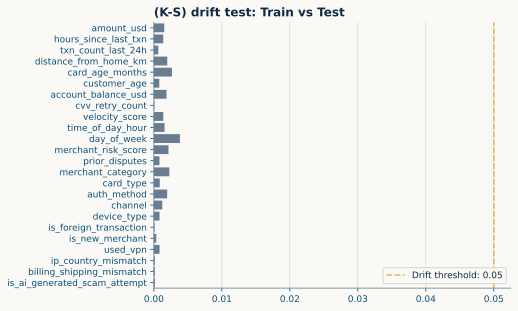

In [17]:
## -- Drift test for TRAIN & TEST --
ks_driftcheck(train, test, "Test", base_cols)

                  feature	   ks-stat	drift
     --------------------	   -------	-------
               amount_usd	   0.38307	⚠️ Drift
     hours_since_last_txn	   0.11316	⚠️ Drift
       txn_count_last_24h	   0.06444	⚠️ Drift
    distance_from_home_km	   0.15931	⚠️ Drift
          card_age_months	    0.0474	✅ Safe!
             customer_age	    0.0695	⚠️ Drift
      account_balance_usd	   0.18798	⚠️ Drift
          cvv_retry_count	   0.08442	⚠️ Drift
           velocity_score	   0.04418	✅ Safe!
         time_of_day_hour	   0.01716	✅ Safe!
              day_of_week	   0.00494	✅ Safe!
      merchant_risk_score	   0.09018	⚠️ Drift
           prior_disputes	   0.10065	⚠️ Drift
        merchant_category	    0.0804	⚠️ Drift
                card_type	   0.07204	⚠️ Drift
              auth_method	   0.02237	✅ Safe!
                  channel	   0.08628	⚠️ Drift
              device_type	   0.04367	✅ Safe!
   is_foreign_transaction	   0.04472	✅ Safe!
          is_new_merchant	   0.07758	⚠️ Drift

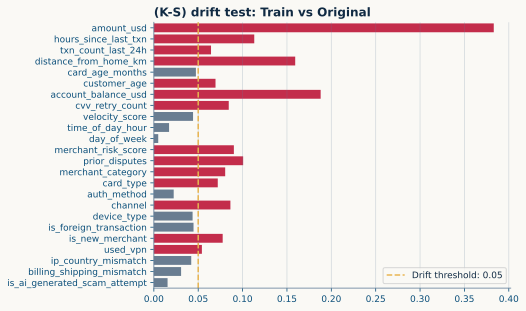

In [18]:
## -- Drift test for TRAIN & ORIGINAL --
ks_driftcheck(train, orig, "Original", base_cols)

In [ ]:
# try:
#     from evidently import Dataset, DataDefinition, Report
#     from evidently.presets import DataDriftPreset, DataSummaryPreset
# except:
#     !uv pip install --system -q evidently
#     from evidently import Dataset, DataDefinition, Report
#     from evidently.presets import DataDriftPreset, DataSummaryPreset

# def evid_driftcheck(df_1, df_2, features, nums, cats):

#     schema = DataDefinition(
#         numerical_columns=nums,
#         categorical_columns=cats,
#         # classification=[BinaryClassification(target="target", prediction_labels="prediction")]
#     )

#     train_df = Dataset.from_pandas(df_1[features], data_definition=schema)
#     test_df  = Dataset.from_pandas(df_2[features], data_definition=schema)

#     report   = Report([DataDriftPreset()])
#     my_eval  = report.run(train_df, test_df)

#     return my_eval

# print("'evidently' Drift-Check function ready!")

In [ ]:
# ## -- Drift: 'train' & 'test' datasets --
# drift_train_test = evid_driftcheck(train, test, base_cols, num_cols, cat_cols+bool_cols)
# display(drift_train_test)

In [ ]:
# ## -- Drift: 'train' & 'orig' datasets --
# drift_train_orig = evid_driftcheck(train, orig, base_cols, num_cols, cat_cols+bool_cols)
# display(drift_train_orig)

## 2. Permutation Importances

In [19]:
from sklearn.inspection import permutation_importance

def plot_permutation_importance(model, X_test, y_test, plot_bar=False):
    model_imp = pd.Series(model.feature_importances_, index=X_test.columns).sort_values()
    
    print("⧗ Training feature permut... ", end="")

    ## -- Compute Permutation Importances --
    result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=10,
        # sample_weight=get_weights(y_test, y),
        scoring="roc_auc",
        random_state=42,
        #n_jobs=-1
    )
    perm_sorted_idx = result.importances_mean.argsort()
    print("Complete!")

    fig, axs = plt.subplots(1, 2, figsize=(12, len(model_imp)*0.25))

    model_imp.plot.barh(ax=axs[0])
    axs[0].set_xlabel("xgb importance")

    perm_imp = pd.Series(
        result.importances_mean[perm_sorted_idx],
        index=X_test.columns[perm_sorted_idx],
    )

    if plot_bar:
        perm_imp.plot.barh(ax=axs[1])
    else:
        axs[1].boxplot(
            result.importances[perm_sorted_idx].T,
            tick_labels=X_test.columns[perm_sorted_idx],
            orientation="horizontal", whis=(0, 100)
        )

    axs[1].axvline(x=0, linestyle="--", color=CRIM)
    axs[1].set_xlabel("permutaion importance")

    fig.suptitle("XGB impurity-based - vs - Permutation on valid data", weight="semibold")
    _ = fig.tight_layout()
    plt.show()

    return perm_imp

print("Permutation function ready!")

Permutation function ready!


In [ ]:
%%time

X = train[base_cols]
y = train[TARGET]

for c in cat_cols+bool_cols:
    X[c], _ = X[c].factorize(sort=True)
    X[c] = X[c].astype("category")

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# imputer = SimpleImputer(strategy="median")
# X_train['Arrival Delay in Minutes'] = imputer.fit_transform(X_train[['Arrival Delay in Minutes']])
# X_test['Arrival Delay in Minutes']  = imputer.transform(X_test[['Arrival Delay in Minutes']])

## -- Compute Model Importances --
print("⧗ Training xgboost (base)... ", end="")
params = {
    'objective': "binary:logistic",
    'enable_categorical': True,
    'eval_metric': 'auc',
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'importance_type': 'gain',
    'random_state': 42,
    'verbosity': 0,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
}

xgb_model = xgb.XGBClassifier(**params)
xgb_model.fit(X_train, y_train)
print("Complete!")

perm_imp = plot_permutation_importance(xgb_model, X_test, y_test, plot_bar=True)

## 2. SHAP VALUES

In [21]:
try:
    import shap
except:
    !uv pip install --system -q shap
    import shap

shap.initjs()

In [22]:
y_sample = y_test.sample(1000, random_state=42)
y_sample.iloc[320:330]

291011    0.0
411391    0.0
55        1.0
22646     0.0
509802    0.0
403343    0.0
476569    0.0
659053    0.0
21448     0.0
505036    0.0
Name: is_fraud, dtype: float64

In [ ]:
## -- Plot SHAP values --
IDX      = y_sample.index
MAX      = min(25, len(base_cols))
INSTANCE = 322

explainer = shap.TreeExplainer(xgb_model)
explanation = explainer(X_test.loc[IDX])

## -- Bar plot --
plt.subplot(121)
shap.plots.bar(
    explanation[INSTANCE],
    max_display=MAX,
    show=False,
)
plt.title(f"Instance: {INSTANCE} | Target Label: {y_test.loc[IDX[INSTANCE]]}", loc="left")

## -- Beeswarm plot --
plt.subplot(122)
shap.plots.beeswarm(
    explanation,
    max_display=MAX,
    order=explanation.abs.max(0),
    alpha=0.25,
    plot_size=(15, 6),
    color_bar=False,
    show=False,
)
plt.title("Most impactful features", loc="left")
# plt.suptitle(f"XGBoost shap values : Feature impact on model predictions",
#              fontweight="bold", fontsize=15, color=CRIM)

plt.tight_layout(pad=2.5)
plt.show()

shap.plots.force(
    explanation[INSTANCE],
    feature_names=base_cols,
    # contribution_threshold=0.1,
    # matplotlib=True,
)

In [ ]:
## -- Plot 2nd/3rd order (SHAPIQ) values --
from __future__ import annotations

try:
    import shapiq
except:
    !uv pip install --system -q shapiq
    import shapiq

explainer = shapiq.TreeExplainer(model=xgb_model, index="k-SII", min_order=1, max_order=3)
list_of_ivs = explainer.explain_X(X=X_test.loc[IDX].to_numpy(), verbose=True)

plt.figure(figsize=(12, MAX*0.05))
shapiq.plot.bar_plot(
    list_of_interaction_values = list_of_ivs,
    feature_names              = base_cols,
    max_display                = MAX,
    abbreviate                 = False, # d=True
    # global_plot                = False, # d=True
    plot_base_value            = True, # d=False
    show                       = True, # d=False 
)

# plt.tight_layout()
# plt.show()

In [25]:
interact_values = explainer.explain(X_test.loc[IDX[INSTANCE]].to_numpy(), random_state=42)
print(interact_values)

InteractionValues(
    index=k-SII, max_order=3, min_order=1, estimated=False, estimation_budget=None,
    n_players=24, baseline_value=-5.177703499794006,
    Top 10 interactions:
        (11,): 1.521185744644995
        (20,): 1.2774155396505134
        (15,): 0.9153912813697384
        (11, 15): 0.6659093210839133
        (3, 5, 13): -0.2897142486212702
        (7, 11, 15): -0.3087566280328604
        (11, 13): -0.3139238846686942
        (8,): -0.3541050270206665
        (3, 5, 20): -0.42636716383153367
        (3, 13, 20): -0.5783915259915733
)


In [ ]:
# strongest field pairs:
#                 velocity_score x merchant_risk_score          0.0623
#            merchant_risk_score x merchant_category            0.0535
#                   customer_age x velocity_score               0.0365
#                   customer_age x merchant_risk_score          0.0331
#                 velocity_score x auth_method                  0.0306
#            merchant_risk_score x auth_method                  0.0287

In [36]:
col_index_natch = {k: v for k, v in zip(X_test.columns, range(len(X_test.columns)))}
col_index_natch

{'amount_usd': 0,
 'hours_since_last_txn': 1,
 'txn_count_last_24h': 2,
 'distance_from_home_km': 3,
 'card_age_months': 4,
 'customer_age': 5,
 'account_balance_usd': 6,
 'cvv_retry_count': 7,
 'velocity_score': 8,
 'time_of_day_hour': 9,
 'day_of_week': 10,
 'merchant_risk_score': 11,
 'prior_disputes': 12,
 'merchant_category': 13,
 'card_type': 14,
 'auth_method': 15,
 'channel': 16,
 'device_type': 17,
 'is_foreign_transaction': 18,
 'is_new_merchant': 19,
 'used_vpn': 20,
 'ip_country_mismatch': 21,
 'billing_shipping_mismatch': 22,
 'is_ai_generated_scam_attempt': 23}

In [26]:
top_k_interactions, sorted_top_k_interactions = interact_values.get_top_k(10, as_interaction_values=False)
sorted_top_k_interactions

[((11,), np.float64(1.521185744644995)),
 ((20,), np.float64(1.2774155396505134)),
 ((15,), np.float64(0.9153912813697384)),
 ((11, 15), np.float64(0.6659093210839133)),
 ((3, 5, 13), np.float64(-0.2897142486212702)),
 ((7, 11, 15), np.float64(-0.3087566280328604)),
 ((11, 13), np.float64(-0.3139238846686942)),
 ((8,), np.float64(-0.3541050270206665)),
 ((3, 5, 20), np.float64(-0.42636716383153367)),
 ((3, 13, 20), np.float64(-0.5783915259915733))]

In [27]:
top_k_interactions

{(3, 5, 13): np.float64(-0.2897142486212702),
 (3, 5, 20): np.float64(-0.42636716383153367),
 (3, 13, 20): np.float64(-0.5783915259915733),
 (7, 11, 15): np.float64(-0.3087566280328604),
 (8,): np.float64(-0.3541050270206665),
 (11, 13): np.float64(-0.3139238846686942),
 (11, 15): np.float64(0.6659093210839133),
 (11,): np.float64(1.521185744644995),
 (15,): np.float64(0.9153912813697384),
 (20,): np.float64(1.2774155396505134)}

In [34]:
## -- GET TOP INTERACTIONS --
iv_table = pd.DataFrame.from_dict(interact_values.get_n_order(2).dict_values, orient='index')\
             .rename(columns={0: 'score'})\
             .sort_values(by='score', ascending=False)

iv_table

,score
"(11, 15)",0.665909
"(5, 20)",0.276332
"(11, 20)",0.240345
"(15, 20)",0.213516
"(3, 11)",0.174801
...,...
"(4, 20)",-0.059554
"(3, 4)",-0.070734
"(15, 21)",-0.073778
"(8, 20)",-0.128743


In [ ]:
## -- Feature interactions/influence --
shapiq.network_plot(interaction_values=interact_values, feature_names=[*X_test.columns], show=True)
interact_values.plot_force(feature_names=base_cols) # , contribution_threshold=0.1

In [ ]:
# plt.figure(figsize=(16, 6))
shapiq.stacked_bar_plot(
    # interaction_values=interact_values.get_n_order(1), # plot order 1
    interaction_values=interact_values.get_n_order(3, min_order=1), # plot order 2
    # interaction_values=interact_values.get_n_order(2), # plot order 3 
    feature_names=base_cols,
    show=False,
)

plt.tight_layout()
plt.show()

## 2. GAM Partial Effects

In [ ]:
try:
    from pygam import LogisticGAM, s, f, te
except:
    !uv pip install --system -q pygam
    from pygam import LogisticGAM, s, f, te

In [ ]:
def gam_dependence_effect(df, features, target, cats):
    df1 = df.copy()
    t0 = time()
    # Dynamically build the GAM formula based on feature types
    gam_terms = []
    for i, feature_name in enumerate(features):
        if feature_name in cats:
            gam_terms.append(f"f({i})")
        else:
            gam_terms.append(f"s({i})")
    # gam_terms.append(f"te({6}, {11})")
    
    gam_formula = " + ".join(gam_terms)

    for c in cats:
        df1[c] = df1[c].factorize(sort=True)[0]

    for c in features:
        df1[c] = df1[c].fillna(-1)

    X_gam = df1[features].to_numpy()
    y_gam = df1[target].values

    # Evaluate the string formula into actual pygam Term objects
    gam = LogisticGAM(eval(gam_formula), verbose=True)
    gam.fit(X_gam, y_gam)

    rows = (len(features) + 2) // 3 # Calculate rows for subplots dynamically
    fig, axs = plt.subplots(rows, 3, figsize=(12.5, rows*3)) 
    axs = axs.ravel()

    for i, col in enumerate(features):
        XX = gam.generate_X_grid(term=i)
        # pdep = gam.partial_dependence(term=i, X=XX)
        pdep, confi = gam.partial_dependence(term=i, width=0.95)
        axs[i].plot(XX[:, i], pdep)
        axs[i].plot(XX[:, i], confi, c=GOLD, ls="--")
        axs[i].set_title(f"* {col}", loc='left')
        axs[i].set_xlabel(col)
        axs[i].set_ylabel("partial_effect")

    # Hide any unused subplots
    for j in range(len(features), len(axs)):
        fig.delaxes(axs[j])

    plt.tight_layout(pad=1.5)
    plt.savefig("pygam_pdep_plot")
    plt.show()

    print(f"\n⏰ Duration: {(time()-t0)/60:.4f} mins")
    return gam

print("✓ GAM Dependency function ready!")

In [ ]:
gam_ = gam_dependence_effect(pd.concat([X_train, y_train], axis=1), base_cols, TARGET, cat_cols+bool_cols)

In [ ]:
gam_.summary()

In [ ]:
print(gam_.accuracy(X_test, y_test))

In [16]:
# ## -- GET TOP INTERACTIONS --

# top_combos = []
# top_scores = []
# for t in sorted_top_k_interactions:
#     if len(t[0]) == 2:
#         # print(t[0], t[1])
#         top_combos.append(t[0])
#         top_scores.append(t[1])

# idxs = []
# combos = []
# for k in top_combos:
#     get_cols = X_test.iloc[:, [*k]].columns.tolist()
#     combos.append(get_cols)

#     join = '_X_'.join(get_cols)
#     idxs.append(join)

# iv_table = pd.Series(
#     top_scores,
#     index=idxs,
#     name='score').sort_values(ascending=False)

# print(iv_table)

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_valid = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_valid[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_valid[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_valid.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [18]:
def original_TE(
    orig: pd.DataFrame,
    X_train: pd.DataFrame,
    X_valid: pd.DataFrame,
    X_test: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
    ):

    if features is None or len(features) == 0:
        return X_train.copy(), X_valid.copy(), X_test.copy(), []

    if aggs is None or len(aggs) == 0:
        return X_train.copy(), X_valid.copy(), X_test.copy(), []

    X_train_df = X_train.copy()
    X_val_df   = X_valid.copy()
    X_test_df  = X_test.copy()
    ORIG = []

    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc='TE_merging'):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"OTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_train_df = X_train_df.merge(map_df, on=col, how='left')
            X_val_df   = X_val_df.merge(map_df, on=col, how='left')
            X_test_df  = X_test_df.merge(map_df, on=col, how='left')

            ORIG.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in ORIG:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_train_df = fill_conditionally(X_train_df)
        X_val_df   = fill_conditionally(X_val_df)
        X_test_df  = fill_conditionally(X_test_df)

    return X_train_df, X_val_df, X_test_df, ORIG

In [19]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test])
for c in tqdm(cat_cols+bool_cols, desc="factorize_cats"):
    combined[c], _ = pd.factorize(combined[c], sort=True)

train = combined.iloc[:len(train)]
test  = combined.iloc[-len(test):].drop(columns=[TARGET])

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 24


factorize_cats:   0%|          | 0/11 [00:00<?, ?it/s]

Total features after operation: 24


In [20]:
train.shape, test.shape

((699960, 25), (299984, 24))

In [21]:
# ## -- FEATURE INTERACTIONS BASED ON SHAP VALUES --
# combined = pd.concat([trn_1, tst_1]) # , orig

# combo_cols = []

# for idx in iv_table.index[:3]:
#     comb_name = combined.columns[idx[0]] + '_X_' + combined.columns[idx[1]]
#     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
#     combo_cols.append(comb_name)

# # for idx in iv_table.index[-2:]:
# #     comb_name = combined.columns[idx[0]] + '_X_' + combined.columns[idx[1]]
# #     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
# #     combo_cols.append(comb_name)

# # for idx in iv_table.index[:5]:
# #     comb_name = combined.columns[idx[0]] + '-|-' + combined.columns[idx[1]]
# #     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
# #     combo_cols.append(comb_name)

# # for idx in iv_table.index[-3:]:
# #     comb_name = combined.columns[idx[0]] + '-|-' + combined.columns[idx[1]]
# #     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
# #     combo_cols.append(comb_name)

# trn_1 = combined.iloc[:len(trn_1)]
# tst_1 = combined.iloc[len(trn_1):len(train)+len(tst_1)].drop(columns=[TARGET])
# # orig  = combined.iloc[-len(orig):]

# del combined
# print(f"Combo features: {combo_cols}")

# te_cols = combo_cols.copy()

# trn_1.head()

In [26]:
oof_final    = pd.DataFrame()
test_final   = pd.DataFrame()
model_scores = {}

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)
skf

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

# ML TRAINING

In [32]:
## -- TREE MODELS --

tree_models = {
    # "XGB_": xgb.XGBClassifier(
    #     objective="binary:logistic",
    #     eval_metric="auc",
    #     enable_categorical=True,
    #     # learning_rate=0.05,
    #     n_estimators=400,
    #     max_depth=2,
    #     subsample=0.8,
    #     # colsample_bytree=0.8,
    #     random_state=42,
    #     n_jobs=-1,
    #     verbosity=0,
    #     device="cuda" if torch.cuda.is_available() else "cpu",
    # ),
    # "LGB_": lgb.LGBMClassifier(
    #     objective="binary",
    #     metric="auc",
    #     # learning_rate=0.05,
    #     # n_estimators=300,
    #     # max_leaves=4,
    #     subsample=0.8,
    #     colsample_bytree=0.6,
    #     cat_features=cat_cols+bool_cols,
    #     random_state=42,
    #     nthreads=-1,
    #     verbose=-1,
    #     device="cuda" if torch.cuda.is_available() else "cpu",
    # ),
    "CAT_": cgb.CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        learning_rate=0.3,
        reg_lambda=1e-3,
        n_estimators=500,
        max_depth=2,
        cat_features=cat_cols+bool_cols,
        random_state=42,
        thread_count=-1,
        verbose=0,
        allow_writing_files=False,
        task_type="GPU" if torch.cuda.is_available() else "CPU",
    ),
    "RFC_": RandomForestClassifier(
        n_estimators=300,
        # max_depth=4,
        n_jobs=-1,
        random_state=42,
        # verbose=1,
    ),
    # "HIST_": HistGradientBoostingClassifier(
    #     # learning_rate=0.05,
    #     max_iter=700,
    #     max_features=0.6,
    #     max_depth=2,
    #     # early_stopping=False,
    #     random_state=42,
    #     # verbose=2,
    # ),
}

print(f"Tree Models to train: {len(tree_models)}", end=" -> ")
print(list(tree_models.keys()))

Tree Models to train: 2 -> ['CAT_', 'RFC_']


## ~ TREE MODELS

In [ ]:
## -- Initiate GBDTs Training --
TREE_MODELS = {}

desc = "Training Models"

for i, (name, model) in tqdm(enumerate(tree_models.items(), 1), total=len(tree_models), desc=desc):
    print(f"\n[{i}] {name} {'█'*10}", end=" | ")
    t0 = time()

    X = train[FEATURES]
    y = train[TARGET].astype('int8')

    oof_preds   = np.zeros(len(X))
    test_preds  = np.zeros(len(test))
    fold_scores = []

    # print(X.dtypes)

    for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_trn, X_val = X.iloc[trn_idx], X.iloc[val_idx]
        y_trn, y_val = y.iloc[trn_idx], y.iloc[val_idx]
        X_test = test[FEATURES].copy()

        # ## -- OPTION A: Concatenate original data --
        # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

        # # -- TE Opt1. -> Using CUSTOM --
        # te_cols = num_cols
        # if fold == 1: print(f"⧗ Target Encoding ({len(te_cols)}) features... ", end="")
        # TE_enc = TargetEncoder(te_cols, cv=5, smooth='auto', aggs=['mean'], drop_original=False)
        # X_trn  = TE_enc.fit_transform(X_trn, y_trn)
        # X_val  = TE_enc.transform(X_val)
        # X_test = TE_enc.transform(X_test)

        if 'CAT' not in name:
            X_trn[cat_cols] = X_trn[cat_cols].astype("category")
            X_val[cat_cols] = X_val[cat_cols].astype("category")
            X_test[cat_cols] = X_test[cat_cols].astype("category")

        if fold == 1: print(f"{X_trn.shape}")

        print(f" • Fold {fold}/{FOLDS}", end=" ")

        seeder = 42 #+ (fold-1)
        # model.random_state = seeder

        model.fit(X_trn, y_trn)
        oof_preds[val_idx] = model.predict_proba(X_val)[:, 1]
        test_preds += model.predict_proba(X_test)[:, 1]

        fold_score = roc_auc_score(y_val, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"seed={seeder}", end=" | ")
        print(f"AUC: {fold_score:.5f}")

    test_preds /= FOLDS

    ## -- After all folds --
    oof_score = np.round(roc_auc_score(y, oof_preds), 5)
    avg_score = np.round(np.mean(fold_scores), 5)
    std_score = np.round(np.std(fold_scores), 5)

    n = name + str(avg_score).split(".")[1]

    print(f"{'-'*31}")
    print(f"OOF Score: {oof_score}")
    print(f"AVG Score: {avg_score} ± {std_score}")
    print(f"{'-'*31}")
    # if 'log' in name:
    #     print(f"Best 'C': {lr_model[-1].C_}") 
    print(f"Duration: {(time()-t0)/60:.2f} mins")

    _, axs = plt.subplots(1, 3, figsize=(12, 3.5)) #, width_ratios=[0.6,0.4]
    pred_labels = (oof_preds >= 0.5).astype('int8')

    CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
    axs[0].set_title(f"{n}: Calibration", loc='left')

    RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
    axs[1].set_title(f"{n}: ROC Curve", loc='left')

    sns.histplot(test_preds, bins=50, ax=axs[2])
    axs[2].set_title(f"{n}: Distribution", loc='left')

    plt.tight_layout()
    plt.show()

    X_train_cols    = X_trn.columns.tolist()
    oof_final[n]    = oof_preds
    test_final[n]   = test_preds
    TREE_MODELS[n]  = model
    model_scores[n] = avg_score

    gc.collect()

del oof_preds, test_preds, X_trn, X_val, X_test #, model, te_cols

In [34]:
# BASE 21 Multi (42+fold) --
# XGB_945573

# BASE 21 Single (42) --
# XGB_94601  LGB_94538  HIST_94658  CAT_94649

display(oof_final.head(3))
print()
display(test_final.head(3))

,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658,CAT_94665,RFC_89134
0,0.000287,0.000676,0.000244,0.000000,0.000545,0.000226,0.010551
1,0.000569,0.001254,0.000920,0.000000,0.000636,0.000617,0.013795
2,0.006874,0.009640,0.007929,0.026667,0.009233,0.008111,0.018807


,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658,CAT_94665,RFC_89134
0,0.000237,0.000456,0.000234,0.000000,0.000308,0.000195,0.012110
1,0.000065,0.000334,0.000083,0.000667,0.000199,0.000082,0.010770
2,0.077128,0.092698,0.079190,0.026667,0.083767,0.080369,0.013482


In [ ]:
## -- Plot Feature Importances --

plot_trees = {k: v for k, v in TREE_MODELS.items() if 'HIST' not in k}
MAX = min(25, len(base_cols))

rows = len(plot_trees) // 2 # Calculate rows for subplots dynamically
fig, axs = plt.subplots(rows, 2, figsize=(13, rows*5))
axs = axs.ravel()

for i, (k, v) in enumerate(plot_trees.items()):
    ## -- xgboost --
    if "XGB" in k:
        xgb.plot_importance(
            v, max_num_features=MAX,
            importance_type="gain",
            title="",
            height=0.5, show_values=False, ax=axs[i],
        )

    ## -- lightgbm --
    elif "LGB" in k:
        lgb.plot_importance(
            v, max_num_features=MAX,
            importance_type="gain",
            title="",
            height=0.5, precision=0, ax=axs[i],
        )
        axs[i].set_ylabel('')

    ## -- catboost --
    elif "CAT" in k:
        cat_imp_df = v.get_feature_importance(prettified=True).iloc[:MAX]
        sns.barplot(data=cat_imp_df, x="Importances", y="Feature Id", width=0.5, ax=axs[i])
        # axs[i].set_title("CAT: importances")
        axs[i].set_ylabel("")

    ## -- random forest --
    elif "RFC" in k:
        rf_dicts = dict(zip(X_train_cols, v.feature_importances_))
        rf_imp_df = pd.DataFrame.from_dict(rf_dicts, orient="index", columns=["score"])\
                                .sort_values("score", ascending=False).iloc[:MAX]
        sns.barplot(rf_imp_df, x=rf_imp_df.score, y=rf_imp_df.index, width=0.5, ax=axs[i])
        axs[i].set_ylabel("")
    else:
        continue
        
    axs[i].set_title(f"{k}", loc='left')
    plt.tight_layout(h_pad=2.0)

# Hide any unused subplots
for j in range(len(plot_trees), len(axs)):
    axs[j].axis('off')

plt.show()

## ~ LINEAR MODELS

In [140]:
## -- FEATURE INTERACTIONS BASED ON SHAP VALUES --
# combined = pd.concat([trn_2, tst_2]) # , orig

# combo_cols = []

# for idx in iv_table.index[:5]:
#     comb_name = combined.columns[idx[0]] + '_X_' + combined.columns[idx[1]]
#     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
#     combo_cols.append(comb_name)

# for idx in iv_table.index[-2:]:
#     comb_name = combined.columns[idx[0]] + '_X_' + combined.columns[idx[1]]
#     combined[comb_name] = combined.iloc[:, idx[0]].astype(str) + '_' + combined.iloc[:, idx[1]].astype(str)
#     combo_cols.append(comb_name)

# print(f"Combo features: {combo_cols}")

# poly_feats = ["Age"]
# for col in poly_feats:
#     p2_col = f"squared_{col}"
#     train_2[p2_col] = train_2[col] ** 2
#     test_2[p2_col]  = test_2[col] ** 2
#     print(f"+++ power^2: {col} --- min={min(train_2[p2_col]):.6g} | max={max(train_2[p2_col]):.6g}")

#     p3_col = f"cubed_{col}"
#     train_2[p3_col] = train_2[col] ** 3
#     test_2[p3_col]  = test_2[col] ** 3
#     print(f"+++ power^3: {col} --- min={min(train_2[p3_col]):.6g} | max={max(train_2[p3_col]):.6g}")

# # # # Add the binned column to your training dataframe
# # # bin_feats = ['Annual_Income_USD']
# # # bins_     = [5]
# # # bin_cats  = []

# # # for col in bin_feats:
# # #     for bin_ in bins_:
# # #         n = f"{col}_bin{bin_}"
# # #         train_2[n], bin_edges = pd.cut(train_2[col], bins=bin_, duplicates='drop', include_lowest=True, retbins=True)
# # #         # Apply the saved bin edges to the test data
# # #         test_2[n] = pd.cut(test_2[col], bins=bin_edges)
# # #         bin_cats.append(n)
# # # cat_cols.extend(bin_cats)

In [141]:
# FEATURES_2 = [c for c in trn_2.columns if c not in [ID, TARGET]]
# print("✓ Total Features:", len(FEATURES_2))

# trn_2.head()

In [36]:
## -- Linear Models --
linear_models = {
    # "NAIVE_": GaussianNB(),
    "LOGIT_": LogisticRegression(
        # class_weight='balanced',
        # max_iter=1000,
        # C=0.1,
        n_jobs=-1,
        random_state=42,
    ),
    "LOGIT2_": LogisticRegression(
        solver='newton-cholesky',
        # class_weight='balanced',
        # max_iter=1000,
        # C=0.1,
        n_jobs=-1,
        random_state=42,
    ),
    "MLP_": MLPClassifier(
        hidden_layer_sizes=(len(FEATURES)*2, len(FEATURES)//2),
        max_iter=50,
        activation='logistic', # d='relu'
        # alpha=0.001, # d=0.0001
        random_state=42,
    ),
    # "KNN_1_": KNeighborsClassifier(
    #     # n_neighbors=10,
    #     # weights='distance',
    #     # algorithm="auto",
    #     n_jobs=-1,
    # ),
}

print(f"Linear Models ({len(linear_models)}): ", end="")
print(list(linear_models.keys()))

Linear Models (3): ['LOGIT_', 'LOGIT2_', 'MLP_']


In [ ]:
## -- Initiate training --
LINEAR_MODELS = {}

for i, (name, mod) in tqdm(enumerate(linear_models.items(), 1), total=len(linear_models)):
    print(f"\n[{i}] {name} {'█'*10} | ", end="")
    t0 = time()

    X = train[FEATURES]
    y = train[TARGET].astype('int8')

    oof_preds   = np.zeros(len(X))
    test_preds  = np.zeros(len(test))
    fold_scores = []

    for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_trn, X_val = X.iloc[trn_idx], X.iloc[val_idx]
        y_trn, y_val = y.iloc[trn_idx], y.iloc[val_idx]
        X_test = test[FEATURES].copy()

        # large_cols = ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
        # for col in large_cols:
        #     log_col = f"log_{col}"
        #     X_train[log_col] = np.log1p(X_train[col])
        #     X_valid[log_col] = np.log1p(X_valid[col])
        #     X_test[log_col]  = np.log1p(X_test[col])

        # for col in ["Age"]:
        #     sqd_col = f"cubed_{col}"
        #     X_train[sqd_col] = X_train[col] ** 3
        #     X_valid[sqd_col] = X_valid[col] ** 3
        #     X_test[sqd_col]  = X_test[col] ** 3

        # # -- TE Opt1. -> Using CUSTOM --
        # if fold == 1 and "te_cols" in globals():
        #     print(f"⧗ Target Encoding ({len(te_cols)}) features...")
        #     TE = TargetEncoder(te_cols, cv=5, smooth='auto', aggs=['mean'], drop_original=False)
        #     X_trn = TE.fit_transform(X_trn, y_trn)
        #     X_val = TE.transform(X_val)
        #     X_test = TE.transform(X_test)

        te_features = [c for c in X_trn.columns if c.startswith(('TE_', 'oTE_'))]

        if fold == 1:
            print(X_trn.shape)

        ## -- Define encoders --
        USE_SPARSE  = False if 'NAIVE' in name else True
        one_hot_enc = OneHotEncoder(handle_unknown="ignore", drop='if_binary', sparse_output=USE_SPARSE)
        num_imputer = SimpleImputer(strategy="median")
        scaler_enc  = StandardScaler()
        # num_imputer = IterativeImputer(max_iter=50, tol=1e-4, random_state=0, add_indicator=True)
        # cat_imputer = SimpleImputer(strategy="constant", fill_value="MISSING", add_indicator=False)
        pwr_scaler  = PowerTransformer()
        qnt_scaler  = QuantileTransformer(n_quantiles=5, random_state=42)
        ## ------------------------------------------------------------------------
        sca_transformer = make_pipeline(scaler_enc)
        qnt_transformer = make_pipeline(qnt_scaler)
        pwr_transformer = make_pipeline(pwr_scaler)

        cat_transformer = make_pipeline(one_hot_enc)
        num_transformer = make_pipeline(num_imputer, scaler_enc) # qnt_scaler
        # num_cat_transformer = make_pipeline(num_cat_imputer, one_hot_enc)
        ## ------------------------------------------------------------------------
        if 'LOGIT' in name:
            new_cat_cols = [c for c in base_cols if X_trn[c].nunique() <= 100]
        else:
            new_cat_cols = cat_cols+bool_cols

        new_num_cols = X_trn.columns.difference(new_cat_cols, sort=False) #.tolist()
        ## ------------------------------------------------------------------------
        preprocessor = make_column_transformer(
                (num_transformer, new_num_cols),
                (cat_transformer, new_cat_cols),
                # ('sca', sca_transformer, new_num_cols),
            remainder="passthrough",
            verbose_feature_names_out=False,
            n_jobs=-1,
        )

        # if 'LOGIT' in name or 'MLP' in name:
        #     seeder = 42 #+ (fold-1)
        #     mod.random_state = seeder

        model = make_pipeline(preprocessor, mod)
        ## ------------------------------------------------------------------------
        model.fit(X_trn, y_trn)
        features_used = model.named_steps['columntransformer'].get_feature_names_out()
        if fold == 1:
            print(f"-> Total expanded features: {len(features_used)}")
            
        print(f" • Fold {fold}/{FOLDS}", end=" ")
        ## ------------------------------------------------------------------------
        oof_preds[val_idx] = model.predict_proba(X_val)[:, 1]
        test_preds += model.predict_proba(X_test)[:, 1]

        fold_score = roc_auc_score(y_val, oof_preds[val_idx])
        fold_scores.append(fold_score)

        if 'NAIVE' in name:
            best_iter = model[-1].n_features_in_
        elif 'KNN' in name:
            best_iter = model[-1].n_samples_fit_
        else:
            best_iter = model[-1].n_iter_

        print(f"AUC: {fold_score:.5f} | seed={seeder}, iter={best_iter}")


    test_preds /= FOLDS

    ## -- After all folds --
    oof_score = np.round(roc_auc_score(y, oof_preds), 5)
    avg_score = np.round(np.mean(fold_scores), 5)
    std_score = np.round(np.std(fold_scores), 5)
    
    n = name + str(avg_score).split(".")[1]

    print(f"{'-'*31}")
    print(f"OOF Score: {oof_score}")
    print(f"AVG Score: {avg_score} ± {std_score}")
    print(f"{'-'*31}")
    # if 'log' in name:
    #     print(f"Best 'C': {lr_model[-1].C_}") 
    print(f"Duration: {(time()-t0)/60:.2f} mins")

    _, axs = plt.subplots(1, 3, figsize=(12, 3.5)) #, width_ratios=[0.6,0.4]
    # Right: Confusion matrix (threshold = 0.5)
    pred_labels = (oof_preds >= 0.5).astype('int8')

    CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
    axs[0].set_title(f"{n}: Calibration", loc='left')

    # Left: ROC curve
    RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
    axs[1].set_title(f"{n}: ROC Curve", loc='left')
    # axs[1].grid(False)

    sns.histplot(test_preds, bins=50, ax=axs[2])
    axs[2].set_title(f"{n}: Distribution", loc='left')

    plt.tight_layout()
    plt.show()

    oof_final[n]     = oof_preds
    test_final[n]    = test_preds
    model_scores[n]  = avg_score
    LINEAR_MODELS[n] = model

    gc.collect()

In [38]:
# -> Total expanded features: 212
# -------------------------------
# OOF Score: 0.94352
# AVG Score: 0.94355 ± 0.00363
# -------------------------------
# Duration: 0.56 mins

oof_final.head(3)

,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658,CAT_94665,RFC_89134,LOGIT_94355,LOGIT2_94432,MLP_94267
0,0.000287,0.000676,0.000244,0.000000,0.000545,0.000226,0.010551,0.000344,0.000359,0.000274
1,0.000569,0.001254,0.000920,0.000000,0.000636,0.000617,0.013795,0.000703,0.000331,0.000521
2,0.006874,0.009640,0.007929,0.026667,0.009233,0.008111,0.018807,0.009483,0.010293,0.002839


In [ ]:
## -- Feature Coefs: Linear models --
for i, name in enumerate(list(LINEAR_MODELS.keys())):
    if "LOGIT" in name:
        coef_dict = dict(
            zip(LINEAR_MODELS[name][0].get_feature_names_out(), LINEAR_MODELS[name][-1].coef_[0])
        )
    elif "MLP" in name:
        coef_dict = dict(
            zip(LINEAR_MODELS[name][0].get_feature_names_out(), LINEAR_MODELS[name][-1].coefs_[0][0])
        )
    else:
        continue

    reg_imp = pd.Series(coef_dict).abs().sort_values(ascending=False).iloc[:20]

    plt.figure(figsize=(12, len(reg_imp)*0.3))
    ax = sns.barplot(reg_imp, orient="h", palette="plasma")
    ax.set_ylabel("Feature")
    ax.set_title(f"{name} - Feature coefs (abs)", loc='left')
    ax.grid()

    for i, v in enumerate(reg_imp.values):
        ax.text(v+1e-2, i, f"{v:.3f}", va="center")

    plt.show()
    print()

In [244]:
# # drop_cols = [c for c in oof_final.columns if c in [*LINEAR_MODELS.keys()]]
# drop_cols = [c for c in oof_final.columns if 'LOGIT_' in c or 'MLP_' in c or 'NAIVE_' in c]

# model_scores = {k: v for k, v in model_scores.items() if k not in drop_cols }
# oof_final = oof_final.drop(columns=drop_cols)
# test_final = test_final.drop(columns=drop_cols)

# oof_final.head(3)

,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658
0,0.000287,0.000676,0.000244,0.000000,0.000545
1,0.000569,0.001254,0.000920,0.000000,0.000636
2,0.006874,0.009640,0.007929,0.026667,0.009233


In [70]:
pd.DataFrame.from_dict(model_scores, orient='index').style.background_gradient(cmap='YlOrBr_r')

,0
XGB_94601,0.946010
LGB_94538,0.945380
CAT_94649,0.946490
RFC_92089,0.920890
HIST_94658,0.946580
CAT_94665,0.946650
RFC_89134,0.891340
LOGIT_94355,0.943550
LOGIT2_94432,0.944320
MLP_94267,0.942670


# ~ STACKING

In [71]:
# from scipy.stats import rankdata

# Cs = (0.001, 0.01, 0.1, 1.0)
# # USE_L1_L2 = True

# ## -- Search for best C --
# logit_cv = LogisticRegressionCV(
#     Cs=Cs,
#     cv=skf,
#     max_iter=1000,
#     # class_weight="balanced",
#     # penalty="elasticnet" if USE_L1_L2 else "l2",
#     # solver="saga" if USE_L1_L2 else "lbfgs",
#     # l1_ratios=np.linspace(0, 1, 5) if USE_L1_L2 else None,
#     scoring="roc_auc",
#     random_state=CFG["SEED"],
#     n_jobs=-1,
#     verbose=0,
# )

# model_pipe = make_pipeline(StandardScaler(), logit_cv)

# model_pipe.fit(rankdata(oof_final.to_numpy(), axis=0), train[TARGET])
# print(f"Best C: {model_pipe[-1].C_} | Best L1_ratio: {model_pipe[-1].l1_ratio_}")

In [72]:
# model_pipe[-1].scores_

In [73]:
# cv_scores = [s for s in model_pipe[-1].scores_.values()]

# for i, (c, scores) in enumerate(zip(Cs, cv_scores[0])):
#     avg = sum(scores[i]) / skf.n_splits
#     print(f"{c:>5}: {avg:.6f}")

In [74]:
oof_final

,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658,CAT_94665,RFC_89134,LOGIT_94355,LOGIT2_94432,MLP_94267
0,0.000287,0.000676,0.000244,0.000000,0.000545,0.000226,0.010551,0.000344,0.000359,0.000274
1,0.000569,0.001254,0.000920,0.000000,0.000636,0.000617,0.013795,0.000703,0.000331,0.000521
2,0.006874,0.009640,0.007929,0.026667,0.009233,0.008111,0.018807,0.009483,0.010293,0.002839
3,0.002518,0.002276,0.002084,0.000000,0.002257,0.002416,0.010968,0.001728,0.001912,0.001225
4,0.006160,0.011039,0.010632,0.016667,0.010485,0.011113,0.015968,0.004734,0.005391,0.007131
...,...,...,...,...,...,...,...,...,...,...
699955,0.002337,0.002856,0.002499,0.003333,0.003016,0.002822,0.011232,0.003615,0.001666,0.004481
699956,0.470037,0.553869,0.493485,0.466667,0.588040,0.502668,0.045054,0.866371,0.863004,0.767801
699957,0.005325,0.009663,0.007440,0.023333,0.007331,0.008081,0.016069,0.003179,0.003059,0.004749
699958,0.009122,0.005746,0.010295,0.003333,0.006717,0.008590,0.015600,0.011235,0.010804,0.013281


In [75]:
def prob_to_prob(p, eps=1e-15, clip=30.0):
    p = np.asarray(p)
    p = np.clip(p, eps, 1.0 - eps)
    p = np.log(p / (1 - p))
    return np.clip(p, -clip, clip)

prob_to_prob(oof_final)[:, 0].min(), prob_to_prob(oof_final)[:, 0].max()

(np.float64(-17.045017310614956), np.float64(12.387032919055489))

Stacking models: 10
Fold 1/5 AUC: 0.94601, iter=[20]
Fold 2/5 AUC: 0.94912, iter=[21]
Fold 3/5 AUC: 0.95244, iter=[21]
Fold 4/5 AUC: 0.94770, iter=[21]
Fold 5/5 AUC: 0.94258, iter=[20]
|------------------------------
| OOF AUC: 0.94748
| AVG AUC: 0.94757 ± 0.00327
|------------------------------
| Duration: 8.23 secs


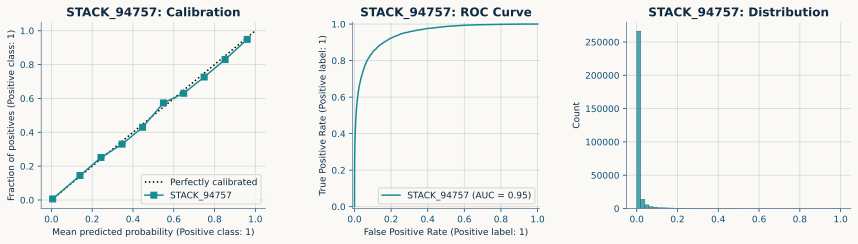

In [155]:
## -- Define Training Parameters --

## -- Check if stack/hill models exist --
drop_cols = [c for c in oof_final.columns if "STACK" in c or "HILL" in c]

model_scores = {k: v for k, v in model_scores.items() if k not in drop_cols }
oof_final  = oof_final.drop(columns=drop_cols)
test_final = test_final.drop(columns=drop_cols)

stack_oof_preds  = np.zeros(len(oof_final))
stack_test_preds = np.zeros(len(test_final))
fold_scores = []

## -- Initiate Training --
t0 = time()

print(f"Stacking models: {oof_final.shape[1]}")
for fold, (trn_idx, val_idx) in enumerate(skf.split(oof_final, train[TARGET]), 1):
    print(f"Fold {fold}/{skf.n_splits} ", end="")

    X_trn, X_val = oof_final.iloc[trn_idx], oof_final.iloc[val_idx]
    y_trn, y_val = train[TARGET].iloc[trn_idx], train[TARGET].iloc[val_idx]
    X_test = test_final.copy()

    X_trn  = prob_to_prob(X_trn)
    X_val  = prob_to_prob(X_val)
    X_test = prob_to_prob(X_test)

    scaler = StandardScaler()
    X_trn = scaler.fit_transform(X_trn, y_trn)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    meta_model = LogisticRegression(
        # C=0.1,
        # "max_iter": 1000,
        # solver='newton-cholesky',
        random_state=42,
    )

    meta_model.fit(X_trn, y_trn)
    stack_oof_preds[val_idx] = meta_model.predict_proba(X_val)[:, 1]
    stack_test_preds += meta_model.predict_proba(X_test)[:, 1]

    oof_score = roc_auc_score(y_val, stack_oof_preds[val_idx])
    fold_scores.append(oof_score)
    print(f"AUC: {oof_score:.5f}, iter={meta_model.n_iter_}")

stack_test_preds /= FOLDS

## -- After all folds --
stack_oof_score = np.round(roc_auc_score(train[TARGET], stack_oof_preds), 5)
stack_avg_score = np.round(np.mean(fold_scores), 5)
stack_std_score = np.round(np.std(fold_scores), 5)

stack_name = 'STACK_' + str(stack_avg_score).split('.')[1]

print(f"|{'-'*30}")
print(f"| OOF AUC: {stack_oof_score}")
print(f"| AVG AUC: {stack_avg_score} ± {stack_std_score}")
print(f"|{'-'*30}")
print(f"| Duration: {(time()-t0):.2f} secs")

_, axs = plt.subplots(1, 3, figsize=(12, 3.5))

CalibrationDisplay.from_predictions(train[TARGET], stack_oof_preds, n_bins=10, name=stack_name, ax=axs[0])
axs[0].set_title(f"{stack_name}: Calibration")

RocCurveDisplay.from_predictions(train[TARGET], stack_oof_preds, name=stack_name, ax=axs[1])
axs[1].set_title(f"{stack_name}: ROC Curve")

sns.histplot(stack_test_preds, bins=50, ax=axs[2])
axs[2].set_title(f"{stack_name}: Distribution")

plt.tight_layout()
plt.show()

In [156]:
oof_final[stack_name]    = stack_oof_preds
test_final[stack_name]   = stack_test_preds
model_scores[stack_name] = stack_avg_score

oof_final.head()

,XGB_94601,LGB_94538,CAT_94649,RFC_92089,HIST_94658,CAT_94665,RFC_89134,LOGIT_94355,LOGIT2_94432,MLP_94267,STACK_94757
0,0.000287,0.000676,0.000244,0.000000,0.000545,0.000226,0.010551,0.000344,0.000359,0.000274,0.000297
1,0.000569,0.001254,0.000920,0.000000,0.000636,0.000617,0.013795,0.000703,0.000331,0.000521,0.000647
2,0.006874,0.009640,0.007929,0.026667,0.009233,0.008111,0.018807,0.009483,0.010293,0.002839,0.009367
3,0.002518,0.002276,0.002084,0.000000,0.002257,0.002416,0.010968,0.001728,0.001912,0.001225,0.002310
4,0.006160,0.011039,0.010632,0.016667,0.010485,0.011113,0.015968,0.004734,0.005391,0.007131,0.008168


# ~ HILLCLIMB

In [157]:
try:
    from hillclimbers import climb_hill, partial
except:
    !pip install -q hillclimbers
    from hillclimbers import climb_hill, partial

In [158]:
%%time

## -- Check if stack/hill models exist --
drop_hill    = [c for c in oof_final.columns if "HILL" in c]
oof_final    = oof_final.drop(columns=drop_hill)
test_final   = test_final.drop(columns=drop_hill)
model_scores = {k: v for k, v in model_scores.items() if k not in drop_hill}

drop_stack = [c for c in oof_final.columns if "STACK" in c]

## -- Run hillclimber --
hc_test_preds, hc_oof_preds = climb_hill(
        train=train,
        target=TARGET,
        oof_pred_df=oof_final.drop(columns=drop_stack),
        test_pred_df=test_final.drop(columns=drop_stack),
        eval_metric=partial(roc_auc_score),
        objective='maximize',
        precision=0.01,
        plot_hill=True,
        plot_hist=False,
        return_oof_preds=True,
        negative_weights=True,
)

   /\  
  /__\  hillclimbers 
 /    \
/______\ 

Models to be ensembled | (10 total): 

CAT_94665:    0.94662 (best solo model)
HIST_94658:   0.94654
CAT_94649:    0.94646
XGB_94601:    0.94598
LGB_94538:    0.94534
LOGIT2_94432: 0.94429
LOGIT_94355:  0.94352
MLP_94267:    0.94245
RFC_92089:    0.92086
RFC_89134:    0.89098

[Data preparation completed successfully] - [Initiate hill climbing] 

Iteration: 1 | Model added: XGB_94601 | Best weight: 0.45 | Best roc_auc_score: 0.94733
Iteration: 2 | Model added: LOGIT2_94432 | Best weight: 0.15 | Best roc_auc_score: 0.94747
Iteration: 3 | Model added: LGB_94538 | Best weight: 0.10 | Best roc_auc_score: 0.94751
Iteration: 4 | Model added: MLP_94267 | Best weight: -0.09 | Best roc_auc_score: 0.94755
Iteration: 5 | Model added: RFC_89134 | Best weight: -0.01 | Best roc_auc_score: 0.94757
Iteration: 6 | Model added: HIST_94658 | Best weight: 0.09 | Best roc_auc_score: 0.94758
Iteration: 7 | Model added: CAT_94649 | Best weight: -0.08 | Best ro

CPU times: user 14min 17s, sys: 1.08 s, total: 14min 18s
Wall time: 14min 19s


In [159]:
hc_score = np.round(roc_auc_score(y, hc_oof_preds), 5)
hillclimb_name = "HILL_" + str(hc_score).split('.')[1]

oof_final[hillclimb_name]  = hc_oof_preds
test_final[hillclimb_name] = hc_test_preds

model_scores[hillclimb_name] = hc_score
hc_score

np.float64(0.94759)

In [160]:
scores_df = pd.DataFrame.from_dict(model_scores, orient='index').reset_index()
scores_df.columns = ['model', 'auc']
scores_df = scores_df.sort_values(by='auc', ascending=False).reset_index(drop=True)
scores_df.style.background_gradient(cmap='YlOrBr_r')

,model,auc
0,HILL_94759,0.947590
1,STACK_94757,0.947570
2,CAT_94665,0.946650
3,HIST_94658,0.946580
4,CAT_94649,0.946490
5,XGB_94601,0.946010
6,LGB_94538,0.945380
7,LOGIT2_94432,0.944320
8,LOGIT_94355,0.943550
9,MLP_94267,0.942670


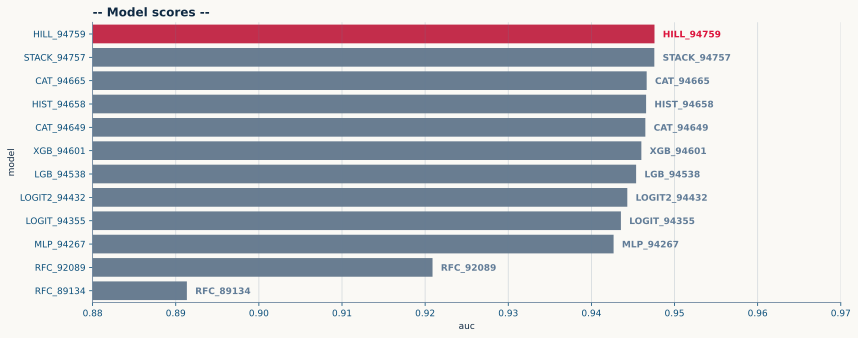

In [161]:
## -- Plot results --

# plt.figure(figsize=(12.5, 4))
# sns.lineplot(
#     scores_df,
#     marker='o',
#     ms=10,
#     mfc=CRIM,
#     # mec=DARK,
#     mew=1.5,
# )
# plt.tick_params('x', rotation=30)
# plt.title("- Model Scores -")

# for i, s in enumerate(scores_df.values):
#     plt.text(scores_df.index[i], s+1e-3, s, va="baseline", ha="center")

# plt.ylim(0.9, 0.97)
# plt.tight_layout()
# plt.show(); print()

max_val = scores_df.auc.values.max()
palette = [CRIM if c == max_val else MUTED for c in scores_df.auc.values]

plt.figure(figsize=(12, len(scores_df)*0.4))

ax1 = sns.barplot(
    x=scores_df.auc,
    y=scores_df.model,
    hue=scores_df.model,
    palette=palette,
    orient="h",
    legend=False,
)

for i, s1 in enumerate(scores_df.auc.values):
    ax1.text(
        s1+1e-3,
        float(i),
        f"{scores_df.model[i]}",
        # f"{scores_df.index[i]}\n{s1:.6f}" if s1 == max_val else f"{scores_df.index[i]}\n{s1:.6f}",
        ha="left",
        va='center_baseline',
        weight="bold",
        color=CRIM if s1 == max_val else MUTED,
    )

plt.xlim((0.88, 0.97))
plt.title(f"-- Model scores --", loc='left')

plt.tight_layout()
plt.show()

# SUBMISSION

In [164]:
## -- Export stacking --

stack_score = str(stack_avg_score).split('.')[1]
stack_oof_preds  = oof_final[stack_name].to_numpy().ravel()
stack_test_preds = test_final[stack_name].to_numpy().ravel()

s_n = f"BASE_STACK_{stack_score}"
np.save(f"oof_{s_n}.npy", stack_oof_preds)
np.save(f"test_{s_n}.npy", stack_test_preds)

submit[TARGET] = stack_test_preds
submit.to_csv(f"submit_{s_n}.csv", index=False)
print(f"--> {s_n} file saved!")

--> BASE_STACK_94757 file saved!


In [165]:
## -- Export hillclimb --

hillclimb_score = str(hc_score).split('.')[1]
hillclimb_oof_preds  = oof_final[hillclimb_name].to_numpy().ravel()
hillclimb_test_preds = test_final[hillclimb_name].to_numpy().ravel()

h_n = f"BASE_HILL_{hillclimb_score}"
np.save(f"oof_{h_n}.npy", hillclimb_oof_preds)
np.save(f"test_{h_n}.npy", hillclimb_test_preds)

submit[TARGET] = hillclimb_test_preds
submit.to_csv(f"submit_{h_n}.csv", index=False)
print(f"--> {h_n} file saved!")

--> BASE_HILL_94759 file saved!


In [ ]:
# ## -- Create Submission files --

# for i, c in enumerate(test_final.columns):
#     submit[TARGET] = test_final[c].values.ravel()
#     submit.to_csv(f"submit_BASE_{c}.csv", index=False)
#     print(f"--> submit_BASE_{c}.csv file saved!")

In [163]:
# !rm -r /kaggle/working/

rm: cannot remove '/kaggle/working/': Device or resource busy
